<a href="https://colab.research.google.com/github/nevita275/ML_20_Nevita/blob/main/JS08/JS08-Tugas%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20 <br> <br>

# TUGAS LAB 1

## Langkah 1: Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

## Langkah 2: Memuat dataset

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("CC_Customer_Dataset.csv")
df.head()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Langkah 3: Eksplorasi data

In [3]:
print("Bentuk data:", df.shape)
print("\nNama kolom:", list(df.columns))
print("\nInfo:")
df.info()
print("\nStatistik deskriptif:")
display(df.describe())
print("\nMissing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Bentuk data: (660, 7)

Nama kolom: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Statistik deskriptif:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000



Missing value per kolom:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Jumlah baris duplikat: 0


## Langkah 4: Pemilihan variabel (“seluruh variabel yang dapat digunakan”)

In [4]:
id_cols = [c for c in df.columns if c.lower().replace(" ", "_") in ("sl_no", "customer_key", "id", "customer_id")]
print("Kolom ID yang dibuang:", id_cols)

X_raw = df.drop(columns=id_cols).select_dtypes(include=np.number)
print("Fitur yang dipakai:", list(X_raw.columns))
X_raw.head()

Kolom ID yang dibuang: ['Sl_No', 'Customer Key']
Fitur yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


## Langkah 5: Standarisasi

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print(X_scaled.shape)

(660, 5)


## Langkah 6: Menentukan jumlah cluster
### 6a. Dendrogram

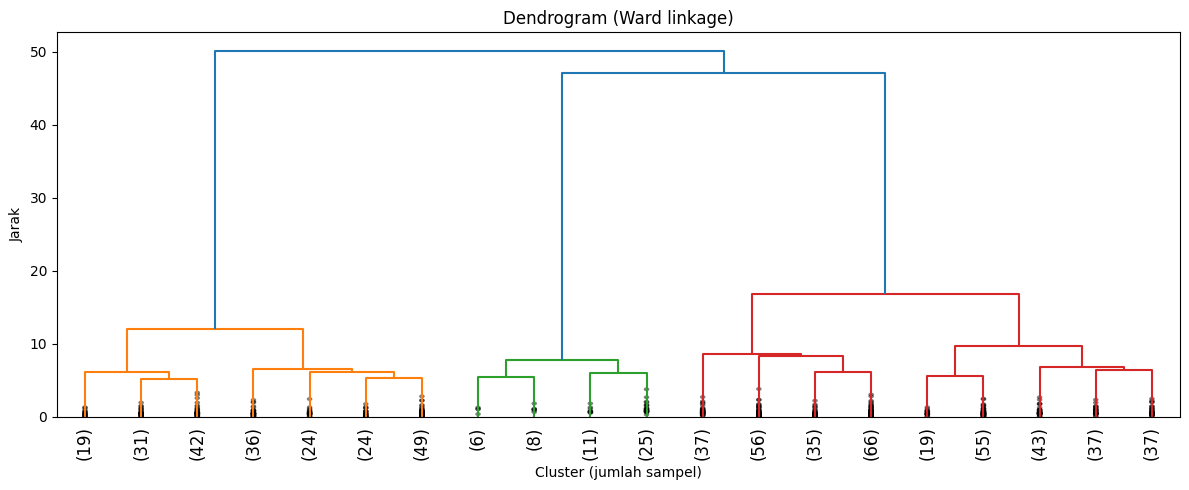

In [6]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, show_contracted=True)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Cluster (jumlah sampel)")
plt.ylabel("Jarak")
plt.tight_layout()
plt.show()

### 6b. Silhouette untuk beberapa nilai k

In [7]:
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    print(f"k={k} | Silhouette={silhouette_score(X_scaled, lab):.4f} | DBI={davies_bouldin_score(X_scaled, lab):.4f}")

k=2 | Silhouette=0.4177 | DBI=0.9326
k=3 | Silhouette=0.5148 | DBI=0.6810
k=4 | Silhouette=0.3481 | DBI=1.1493
k=5 | Silhouette=0.2569 | DBI=1.3851
k=6 | Silhouette=0.2268 | DBI=1.4109
k=7 | Silhouette=0.2163 | DBI=1.4394
k=8 | Silhouette=0.2187 | DBI=1.4489


## Langkah 7: Membuat model Agglomerative Clustering

In [8]:
N_CLUSTERS = 3

model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
labels = model.fit_predict(X_scaled)

df_result = X_raw.copy()
df_result["Cluster"] = labels
print(df_result["Cluster"].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


## Langkah 8: Scatterplot Avg_Credit_Limit vs Total_Credit_Cards

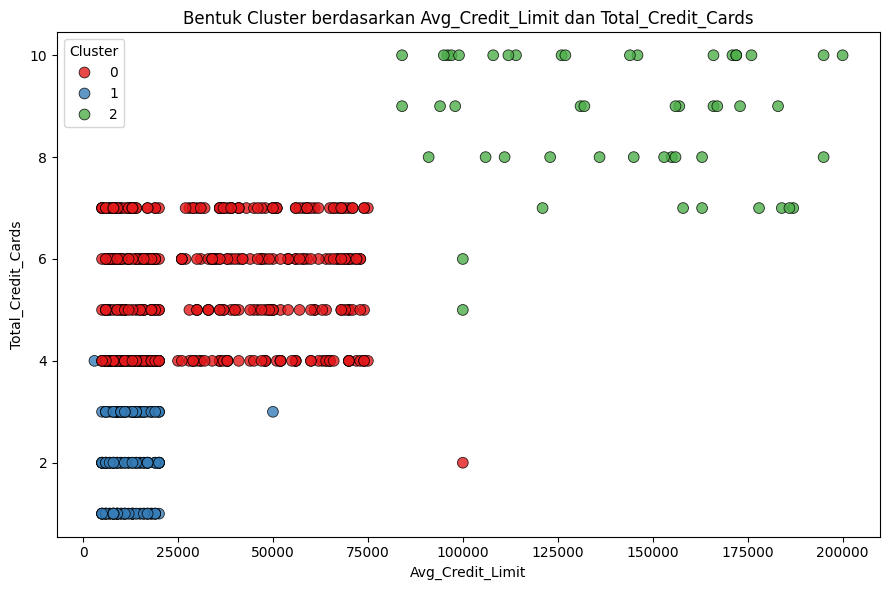

In [10]:
col_x = "Avg_Credit_Limit"
col_y = "Total_Credit_Cards"

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_result, x=col_x, y=col_y,
    hue="Cluster", palette="Set1", s=60, alpha=0.8, edgecolor="k"
)
plt.title("Bentuk Cluster berdasarkan Avg_Credit_Limit dan Total_Credit_Cards")
plt.xlabel(col_x)
plt.ylabel(col_y)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Langkah 9: Silhouette Score dan Davies-Bouldin Index

In [11]:
sil = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)

print(f"Silhouette Score     : {sil:.4f}")
print(f"Davies-Bouldin Index : {dbi:.4f}")

Silhouette Score     : 0.5148
Davies-Bouldin Index : 0.6810


## Langkah 10: Profil cluster

In [12]:
profil = df_result.groupby("Cluster").mean().round(2)
profil["Jumlah"] = df_result["Cluster"].value_counts().sort_index()
display(profil)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Jumlah
Cluster,,,,,,
0,33851.95,5.52,3.49,0.98,1.99,385
1,12151.11,2.42,0.94,3.55,6.86,225
2,141040.00,8.74,0.60,10.90,1.08,50


## Analisis Hasil

**Jumlah cluster.** Dendrogram (Ward linkage) menunjukkan 3 kelompok besar, dan
silhouette tertinggi (0,5148) serta DBI terendah (0,6810) sama-sama di k=3,
sehingga dipilih 3 cluster.

**Bentuk cluster pada scatterplot.** Cluster 1 (biru) berada di limit rendah
(sekitar 3.000-20.000) dengan 1-3 kartu. Cluster 0 (merah) berada di limit
menengah (sekitar 4.000-75.000) dengan 4-7 kartu. Cluster 2 (hijau) berada di
limit tinggi (sekitar 84.000-200.000) dengan 7-10 kartu. Beberapa titik tampak
berada di area cluster lain karena model memakai 5 fitur, sedangkan plot hanya
menampilkan 2 fitur.

**Evaluasi.** Silhouette Score = 0,5148 (struktur cluster cukup jelas) dan
Davies-Bouldin Index = 0,6810 (cluster cukup padat dan terpisah).

**Profil cluster.** Cluster 0 nasabah menengah yang sering ke bank, Cluster 1
nasabah limit kecil yang sering menelepon, Cluster 2 nasabah premium yang
dominan memakai layanan online.